# DFND on the fixed shell: inspect certified controls and raw supports

Does the current implementation agree with the independent small-probe access,
enclosed free-origin and large-probe exclusion controls? Read
[system.ipynb](system.ipynb) for the proofs. This notebook reads its committed
reference and the unchanged input in a separate fresh kernel. It launches no
original provider or server and does not write any frozen artifact.

We inspect the origin-containing carrier cells, raw wet components, exterior
links and public compatibility buckets. A graph skeleton alone does not
certify continuous navigation; the small-probe ray is an independent witness.

In [1]:
import hashlib
import html
import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from pyunitwizard import QuantityRecord
from scipy.spatial import ConvexHull

import topomt as tmt
from topomt import pyunitwizard as puw
from topomt.dfnd import DelaunayFlowNetwork

DATA = Path('artifacts/native_study_v1')
protocol_bytes=(DATA/'protocol.json').read_bytes()
reference_bytes=(DATA/'system_reference.json').read_bytes()
protocol=json.loads(protocol_bytes); reference=json.loads(reference_bytes)
input_bytes=Path(protocol['source_file']).read_bytes(); fixture=json.loads(input_bytes)
assert reference['input_sha256']==hashlib.sha256(input_bytes).hexdigest()==protocol['input_sha256']
assert reference['protocol_sha256']==hashlib.sha256(protocol_bytes).hexdigest()
for relative,digest in protocol['preserved_files'].items():
    assert hashlib.sha256(Path(relative).read_bytes()).hexdigest()==digest

def quantity(record,field,unit):
    return QuantityRecord.from_dict(record).to_quantity(field=field,unit=unit)

def values(record,field,unit):
    return np.asarray(puw.get_value(quantity(record,field,unit),to_unit=unit))

def qrecord(data,unit,field):
    return QuantityRecord.from_quantity(puw.quantity(data,unit),field=field).to_dict()

def table(headers,rows):
    lines=['| '+' | '.join(headers)+' |','| '+' | '.join(['---']*len(headers))+' |']
    lines+=['| '+' | '.join(str(value) for value in row)+' |' for row in rows]
    display(Markdown(chr(10).join(lines)))

coords=values(fixture['coordinates'],'coordinates','angstroms')
radii=values(fixture['atom_radii'],'atom_radii','angstroms')
origin=values(protocol['origin'],'origin','angstroms')
direction=values(reference['escape_witness']['direction'],'direction','dimensionless')
query={key:(quantity(value,key,'angstroms') if isinstance(value,dict) else value)
       for key,value in protocol['query'].items()}
network=DelaunayFlowNetwork.from_coordinates_and_radii(
    quantity(fixture['coordinates'],'coordinates','angstroms'),
    quantity(fixture['atom_radii'],'atom_radii','angstroms'),
    epsilon=quantity(fixture['epsilon'],'epsilon','angstroms'))
# The native carrier coordinates have the explicit nm storage contract.
origin_nm=np.asarray(puw.get_value(quantity(protocol['origin'],'origin','nm'),to_unit='nm'))
vertices=network.atom_coords[network.tetra_atoms]
matrices=np.swapaxes(vertices[:,1:]-vertices[:,:1],1,2)
barycentric=np.linalg.solve(matrices,(origin_nm-vertices[:,0])[:,:,None])[:,:,0]
tolerance=protocol['tolerances']['barycentric_absolute']
containing=set(map(int,np.flatnonzero(np.all(barycentric>=-tolerance,axis=1)&(barycentric.sum(axis=1)<=1+tolerance))))
assert containing
table(['Native input / query','Value'],[['Atoms',len(coords)],['Carrier tetrahedra',network.n_tetrahedra],
    ['Origin-containing cells',sorted(containing)],['min_size',query['min_size']],
    ['Transit policy',query['transit_policy']],['Gate-intrusion policy',query['gate_intrusion_policy']]])

| Native input / query | Value |
| --- | --- |
| Atoms | 72 |
| Carrier tetrahedra | 191 |
| Origin-containing cells | [40] |
| min_size | 0 |
| Transit policy | with_connectors |
| Gate-intrusion policy | flag_only |

## Select the region spatially, before ranking outputs

Barycentric containment identifies the finite carrier cells containing the
declared origin. We inspect the raw wet component containing those cells,
rather than picking the largest output after seeing it. The query keeps
`min_size=0`, explicit zero physical tolerances and the frozen mesh epsilon.
Counts outside the certified central region remain observations.

In [2]:
def observe(probe,min_size=0):
    settings={**query,'min_size':min_size}
    result=network.get_topography(probe_radius=puw.quantity(float(probe),'angstroms'),**settings)
    raw=result['raw']
    central=[component for component in raw['wet_components'] if containing & set(component['tetrahedron_ids'])]
    assert len(central)<=1
    component=central[0] if central else None
    resident_ids=[int(cell['tetrahedron_id']) for cell in raw['tetrahedra'] if cell['residence_state']=='resident']
    observation={'probe_radius':qrecord(float(probe),'angstroms','probe_radius'),
        'raw_component_count':len(raw['wet_components']),'resident_node_count':len(resident_ids),
        'resident_tetrahedron_ids':resident_ids,
        'central_family':component['family'] if component else 'no_wet_component',
        'central_resident_nodes':int(component['n_resident_nodes']) if component else 0,
        'central_tetrahedron_ids':list(map(int,component['tetrahedron_ids'])) if component else [],
        'central_resident_tetrahedron_ids':list(map(int,component['resident_tetrahedron_ids'])) if component else [],
        'central_external_links':int(component['n_external_links']) if component else None,
        'central_solvent_volume_estimate':None if component is None else qrecord(
            float(puw.get_value(puw.quantity(component['volume_solvent_estimate'],'nm**3'),to_unit='angstroms**3')),
            'angstroms**3','central_solvent_volume_estimate'),
        'reported_counts':{key:len(bucket) for key,bucket in result['wet'].items()}}
    return observation,result

anchors=[]; anchor_results=[]
for declared in reference['experiments']:
    probe=float(values(declared['probe_radius'],'probe_radius','angstroms'))
    observed,result=observe(probe)
    observed['experiment_id']=declared['id']
    observed['reference_expectation']=declared['expectation']
    anchors.append(observed); anchor_results.append(result)
assert anchors[0]['central_resident_nodes']>0 and anchors[0]['central_external_links']>0
assert anchors[1]['central_family']=='void' and anchors[1]['central_external_links']==0
assert anchors[1]['central_resident_nodes']>0
assert anchors[2]['raw_component_count']==0 and anchors[2]['resident_node_count']==0
table(['Probe (Å)','Independent control','Raw central family','Central resident cells','Exterior-link clusters','Global raw wet components'],
      [[float(values(observed['probe_radius'],'probe_radius','angstroms')),declared['expectation'],observed['central_family'],
        observed['central_resident_nodes'],observed['central_external_links'],observed['raw_component_count']]
       for observed,declared in zip(anchors,reference['experiments'])])

| Probe (Å) | Independent control | Raw central family | Central resident cells | Exterior-link clusters | Global raw wet components |
| --- | --- | --- | --- | --- | --- |
| 0.05 | origin_free_and_exterior_connected | channel | 128 | 10 | 1 |
| 1.4 | origin_free_and_enclosed | void | 33 | 0 | 1 |
| 5.0 | no_free_probe_center_in_finite_hull | no_wet_component | 0 | None | 0 |

Agreement is checked at the scope of each proof: the small-probe central
component must reach the exterior, the 1.4 Å central component must be sealed,
and the large-probe hull must contain no resident wet component. The enclosed
reference does not prescribe the global number of cavities or exact mouth
count. Exterior-link clusters group contacts and are not independently
established physical mouths.

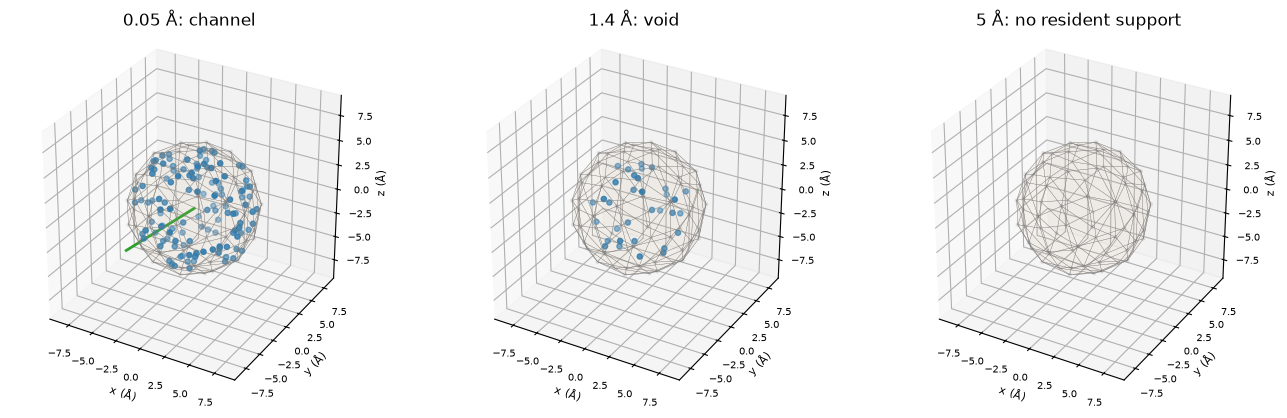

In [3]:
triangles=coords[ConvexHull(coords).simplices]
fig=plt.figure(figsize=(13,4.6))
fig.subplots_adjust(left=.01,right=.97,bottom=.08,top=.92,wspace=.24)
for panel,observed in enumerate(anchors,start=1):
    ax=fig.add_subplot(1,3,panel,projection='3d')
    ax.add_collection3d(Poly3DCollection(triangles,facecolor='tan',edgecolor='grey',alpha=.06,linewidth=.2))
    ax.scatter(*coords.T,s=5,color='dimgray',alpha=.4)
    ids=observed['central_resident_tetrahedron_ids']
    if ids:
        points=coords[network.tetra_atoms[ids]].mean(axis=1)
        ax.scatter(*points.T,s=14,color='tab:blue')
    if panel==1:
        terminal=values(reference['escape_witness']['terminal_point'],'terminal_point','angstroms')
        ax.plot(*np.stack([origin,terminal]).T,color='tab:green',lw=2)
    probe=float(values(observed['probe_radius'],'probe_radius','angstroms'))
    ax.set(xlim=(-9.5,9.5),ylim=(-9.5,9.5),zlim=(-9.5,9.5),xlabel='x (Å)',ylabel='y (Å)',zlabel='z (Å)',
           title=f'{probe:g} Å: '+('no resident support' if not ids else observed['central_family']))
    ax.set_box_aspect((1,1,1))
    ax.tick_params(labelsize=7)
    ax.set_xlabel('x (Å)',fontsize=8,labelpad=0)
    ax.set_ylabel('y (Å)',fontsize=8,labelpad=0)
    ax.set_zlabel('z (Å)',fontsize=8,labelpad=0)
plt.show()

Blue points are resident **carrier-cell centroids**, not cavity boundaries or
alpha spheres. The green line is the independently certified ray at 0.05 Å,
not a path reconstructed from DFND's graph. The last panel has no resident
central support, consistent with the independent full-hull exclusion bound.

## Sweep and the unresolved historical anchor

The original 49-point sweep stays unchanged. Its 0.2 Å anchor does not have
an independent enclosure certificate from our sufficient bounds. We display
its native classification without treating that classification as truth.
Under a fixed query policy, resident-cell availability must be nested as the
probe grows; the number of connected regions need not be monotone.

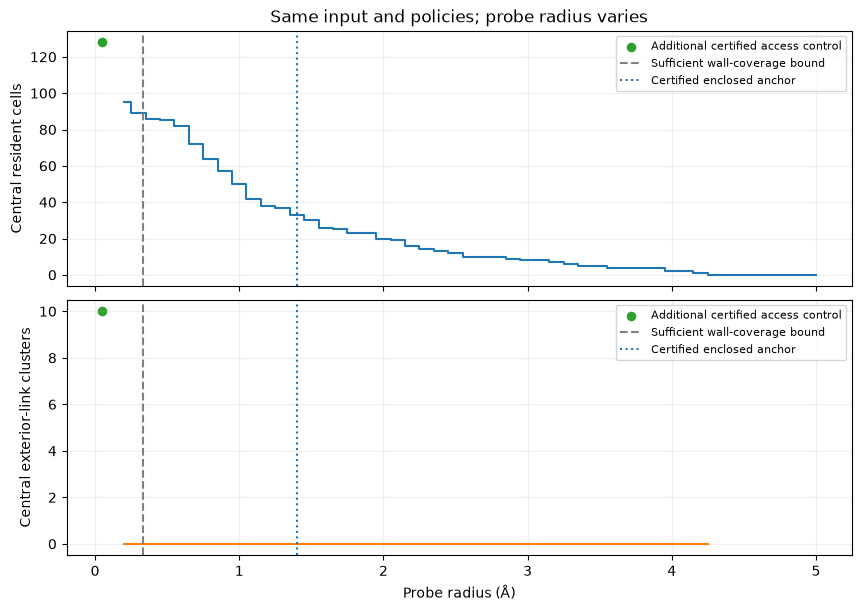

| Historical control | DFND observation | Independent disposition |
| --- | --- | --- |
| 0.2 Å | void | enclosure_unresolved_by_these_sufficient_bounds |

In [4]:
probe_values=values(fixture['probe_sweep'],'probe_sweep','angstroms')
sweep=[]
for probe in probe_values:
    observed,_=observe(float(probe))
    sweep.append(observed)
for before,after in zip(sweep,sweep[1:]):
    assert set(after['resident_tetrahedron_ids']) <= set(before['resident_tetrahedron_ids'])
legacy_control,_=observe(.2)
legacy_control['reference_disposition']=protocol['legacy_control']['expectation']
fig,axes=plt.subplots(2,1,figsize=(8.5,6),sharex=True,constrained_layout=True)
axes[0].step(probe_values,[entry['central_resident_nodes'] for entry in sweep],where='mid')
axes[1].step(probe_values,[np.nan if entry['central_external_links'] is None else entry['central_external_links'] for entry in sweep],where='mid',color='tab:orange')
for ax,key in zip(axes,['central_resident_nodes','central_external_links']):
    ax.scatter([.05],[anchors[0][key]],color='tab:green',s=35,label='Additional certified access control')
    cover=float(values(reference['certificates']['maximum_face_cover_radius'],'maximum_face_cover_radius','angstroms'))
    ax.axvline(cover-radii.min(),color='grey',ls='--',label='Sufficient wall-coverage bound')
    ax.axvline(1.4,color='tab:blue',ls=':',label='Certified enclosed anchor')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
axes[0].set(ylabel='Central resident cells',title='Same input and policies; probe radius varies')
axes[1].set(xlabel='Probe radius (Å)',ylabel='Central exterior-link clusters')
plt.show()
table(['Historical control','DFND observation','Independent disposition'],[[
    '0.2 Å',legacy_control['central_family'],legacy_control['reference_disposition']]])

## Reporting policy and volume meaning

Increasing `min_size` is a display/reporting control. It must retain raw
geometry, source correspondence and the physical result key. We choose a
cutoff just above the observed central resident-cell count, as declared in
the protocol, and check that the raw component survives while its reported
projection is hidden.

DFND's solvent estimate is retained with units and its original meaning.
The reference's bare-free/hull bounds and probe-centre ball volume describe
different sets; none qualifies this estimate to a numerical tolerance.

In [5]:
cutoff=anchors[1]['central_resident_nodes']+1
filtered,filtered_result=observe(1.4,min_size=cutoff)
unchanged=filtered_result['raw']['parameters']['result_key']==anchor_results[1]['raw']['parameters']['result_key']
assert unchanged
assert filtered['central_tetrahedron_ids']==anchors[1]['central_tetrahedron_ids']
assert filtered['central_resident_nodes']==anchors[1]['central_resident_nodes']
assert sum(filtered['reported_counts'].values())==0
reporting_control={'probe_radius':qrecord(1.4,'angstroms','probe_radius'),'min_size':cutoff,
    'geometry_unchanged':unchanged,'raw_central_component_retained':True,
    'raw_component_count':filtered['raw_component_count'],
    'reported_component_count':sum(filtered['reported_counts'].values())}
table(['min_size','Raw central cells','Reported wet records'],[[0,anchors[1]['central_resident_nodes'],sum(anchors[1]['reported_counts'].values())],
    [cutoff,filtered['central_resident_nodes'],sum(filtered['reported_counts'].values())]])
estimate=float(values(anchors[1]['central_solvent_volume_estimate'],'central_solvent_volume_estimate','angstroms**3'))
display(Markdown(f'DFND central solvent-volume estimate at 1.4 Å: **{estimate:.6f} Å³**, with numerical precision still unqualified (#75).'))

| min_size | Raw central cells | Reported wet records |
| --- | --- | --- |
| 0 | 33 | 1 |
| 34 | 33 | 0 |

DFND central solvent-volume estimate at 1.4 Å: **501.680510 Å³**, with numerical precision still unqualified (#75).

## What is established, and what follows

These three independent controls test this fixed input and query policy.
The positive ray does not validate all graph paths; the enclosed reference
does not establish an exact global cavity count; volume precision and the
full synthetic panel remain open (#75/#76). The historical 0.2 Å result
keeps its unresolved reference disposition. No biological generalization
follows from these synthetic controls.

Original-provider and CASTp observations remain in the unchanged historical
notebook at their original versions and dates. A new comparison stage can
be studied separately, with its own input/radius audit. This increment runs
no third party and contacts no server.

A future opening must be derived from this same frozen wall with atom
correspondence preserved and an independent access witness at the selected
probe. Regenerating the jitter after deleting atoms would change the wall
as well as the opening. No opening variant or native kernel change is hidden
in this study.

In [6]:
source_root=Path(tmt.__file__).parent
source_files=sorted(source_root.rglob('*.py'))
digest=hashlib.sha256()
for path in source_files:
    content=path.read_bytes()
    digest.update(path.relative_to(source_root).as_posix().encode()+bytes([0]))
    digest.update(str(len(content)).encode()+bytes([0])+content)
native_report={'schema':'topomt.benchlab.closed-shell-native/1','case_id':'closed_shell','case_version':1,
    'input_sha256':hashlib.sha256(input_bytes).hexdigest(),'reference_sha256':hashlib.sha256(reference_bytes).hexdigest(),
    'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest(),'reference_checks':'passed',
    'software':{'python':platform.python_version(),**{name:version(name) for name in ['topomt','pyunitwizard','numpy','scipy','numba']}},
    'topomt_source':{'scope':'Sorted topomt/**/*.py relative paths and length-delimited bytes','file_count':len(source_files),'sha256':digest.hexdigest()},
    'query':protocol['query'],'epsilon':fixture['epsilon'],'origin_containing_tetrahedra':sorted(containing),
    'anchors':anchors,'legacy_control':legacy_control,'sweep':sweep,'reporting_control':reporting_control,
    'limits':protocol['scope_limits']}
report_text=json.dumps(native_report,indent=2,allow_nan=False)
display({'text/plain':report_text,
         'text/html':'<details><summary>Complete native observations</summary><pre>'+html.escape(report_text)+'</pre></details>'},raw=True)

{
  "schema": "topomt.benchlab.closed-shell-native/1",
  "case_id": "closed_shell",
  "case_version": 1,
  "input_sha256": "ef19995751b2df58c8b1556011f74fa4774e924b9cd499138b8741988b650157",
  "reference_sha256": "2cd156c8b30adf1729f3c5479dba75e6a4853f781f390eef008e9a0ea0176e58",
  "protocol_sha256": "533fd978a20725c36c355e01ad6ed1f05268d61b31bd62f4e77bbddfd8596925",
  "reference_checks": "passed",
  "software": {
    "python": "3.14.10",
    "topomt": "0.5.0+387.gcf4d475.dirty",
    "pyunitwizard": "0.29.1+6.gf82b618",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "numba": "0.68.1"
  },
  "topomt_source": {
    "scope": "Sorted topomt/**/*.py relative paths and length-delimited bytes",
    "file_count": 298,
    "sha256": "15f17f0929574f9dae638fda8a4186a9932b2cd50e53c3231d97929bee7724b9"
  },
  "query": {
    "min_size": 0,
    "transit_policy": "with_connectors",
    "gate_intrusion_policy": "flag_only",
    "dry_adjacency": "face",
    "residence_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "residence_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:3ba2a05b6ed0bfc574a7a7c18c6a68e1"
    },
    "permeability_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "permeability_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:5776c109ac89c18e2c9b62bf36990ac4"
    }
  },
  "epsilon": {
    "manifest": {
      "format": "qrec/0.3",
      "field": "epsilon",
      "unit": "angstrom",
      "si": {
        "factor": 1e-10,
        "offset": 0.0,
        "exponents": {
          "m": 1
        }
      },
      "dtype": "float64",
      "shape": [],
      "blocks": [
        1
      ]
    },
    "values": 1e-06,
    "block_digests": [
      "blake2b-128:fdc4aee404c6c8d3af6c444a146a42d5"
    ],
    "digest": "blake2b-128:afe0b5c20f12a97f318d2e509e8ae42b"
  },
  "origin_containing_tetrahedra": [
    40
  ],
  "anchors": [
    {
      "probe_radius": {
        "manifest": {
          "format": "qrec/0.3",
          "field": "probe_radius",
          "unit": "angstrom",
          "si": {
            "factor": 1e-10,
            "offset": 0.0,
            "exponents": {
              "m": 1
            }
          },
          "dtype": "float64",
          "shape": [],
          "blocks": [
            1
          ]
        },
        "values": 0.05,
        "block_digests": [
          "blake2b-128:4b5217221be043884d11732eae43fcd7"
        ],
        "digest": "blake2b-128:5d533faf0ae670188161d0f9ddee8cd5"
      },
      "raw_component_count": 1,
      "resident_node_count": 128,
      "resident_tetrahedron_ids": [
        1,
        2,
        4,
        7,
        9,
        10,
        11,
        12,
        13,
        14,
        15,
        17,
        18,
        19,
        20,
        22,
        23,
        27,
        28,
        29,
        30,
        31,
        32,
        33,
        34,
        35,
        36,
        37,
        38,
        39,
        40,
        41,
        42,
        43,
        44,
        45,
        46,
        49,
        50,
        51,
        52,
        53,
        54,
        57,
        58,
        59,
        60,
        62,
        63,
        67,
        69,
        70,
        71,
        72,
        73,